# Mean Shift

A clustering algorithm that **finds the number of clusters by itself**. Picture the data as a landscape where dense regions are hills. Put a window of radius `bandwidth` on every point and repeatedly:

> move the point to the **mean** of all data points inside its window

That mean is always uphill (toward where the data is denser), so every point climbs to the nearest **mode** — a local density peak. Points that reach the same peak share a cluster. Seeds that converge to nearly the same place (within one `bandwidth`) are merged, keeping the one with the most points.

| | K-Means | Mean Shift |
|---|---|---|
| Need `k`? | yes | **no** — the single parameter is `bandwidth` |
| Cluster shape | round | any shape the density has |
| Outliers | pull centres | become their own tiny mode (or absorbed) |
| Cost | cheap | `O(n²)` per iteration |

`bandwidth` is the only knob: small gives many fragments, large gives few merged blobs. If omitted it is estimated as the average distance to the `quantile`-th nearest neighbour (`estimate_bandwidth`, same rule as scikit-learn). This implementation uses a flat kernel, like scikit-learn's, so the results line up.

## Usage

```python
# (the class is defined in the Implementation section below)

model = MeanShift(bandwidth=2.0).fit(X)
model.cluster_centers_    # the modes it discovered
model.labels_
model.predict(X_new)      # nearest mode
```

This notebook is self-contained: the explanation, the implementation, the visuals, the scikit-learn check and the tests are all here.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

## Implementation

The whole algorithm, as a plain Python class (numpy only).

In [2]:
import numpy as np


def _distances(A, B):
    return np.sqrt(((A[:, None, :] - B[None, :, :]) ** 2).sum(axis=2))


def estimate_bandwidth(X, quantile=0.3):
    """Mean distance from each point to its ceil(quantile * n)-th nearest neighbour (itself included)."""
    X = np.asarray(X, dtype=float)
    k = max(1, int(len(X) * quantile))
    return np.sort(_distances(X, X), axis=1)[:, k - 1].mean()


class MeanShift:
    """Mode-seeking clustering. Imagine a hill of point density; every point climbs it:

        repeat:  move the point to the MEAN of all data points within `bandwidth` of it

    The mean always lies uphill of the current position (toward denser data), so every point
    ends up on a local density peak (a mode). Points that climb to the same peak form a cluster.
    The number of clusters is not given -- it falls out of the data and the bandwidth.

    bandwidth: radius of the window. Small -> many small clusters, large -> few big ones.
    Defaults to estimate_bandwidth(X). Flat (uniform) kernel.

    ponytail: every point is a seed and distances are recomputed each step, O(n^2) per iteration.
    Bin the seeds on a grid for large n."""

    def __init__(self, bandwidth=None, max_iter=300):
        self.bandwidth = bandwidth
        self.max_iter = max_iter

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        h = self.bandwidth if self.bandwidth is not None else estimate_bandwidth(X)
        self.bandwidth_ = h

        modes = []  # (center, number of points inside its final window)
        for seed in X:
            center = seed.copy()
            for _ in range(self.max_iter):
                inside = X[np.linalg.norm(X - center, axis=1) <= h]
                if len(inside) == 0:
                    break
                new_center = inside.mean(axis=0)
                converged = np.linalg.norm(new_center - center) < 1e-3 * h
                center = new_center
                if converged:
                    break
            modes.append((center, int((np.linalg.norm(X - center, axis=1) <= h).sum())))

        # many seeds reach (almost) the same peak: keep the strongest, drop anything within h of it
        modes.sort(key=lambda m: (-m[1], tuple(m[0])))
        kept = []
        for center, _ in modes:
            if all(np.linalg.norm(center - c) > h for c in kept):
                kept.append(center)
        self.cluster_centers_ = np.array(kept)
        self.labels_ = self.predict(X)
        return self

    def predict(self, X):
        return _distances(np.asarray(X, dtype=float), self.cluster_centers_).argmin(axis=1)

## See it work

### 1. Modes of a density

Mean shift treats the data as samples from a density and climbs to its peaks (modes): every point repeatedly moves to the mean of the points within `bandwidth`, so it slides uphill to the nearest mode. The number of clusters is the number of modes found, not something you specify. Here the red crosses are the modes and the shading is a kernel density estimate with the same bandwidth.

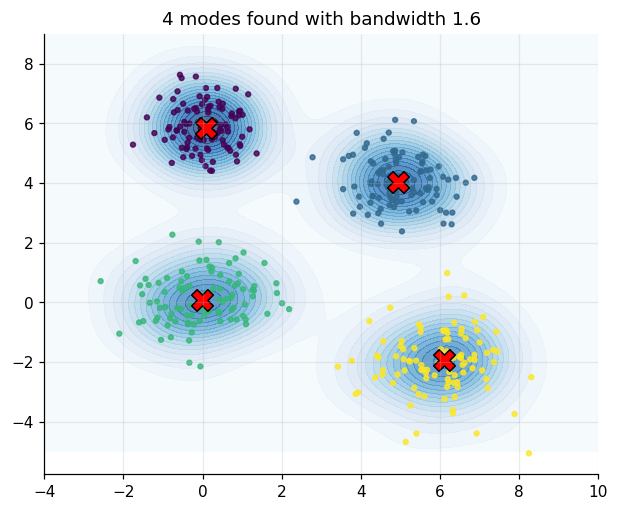

In [3]:
from sklearn.datasets import make_blobs

X, _ = make_blobs(n_samples=400, centers=[[0, 0], [5, 4], [0, 6], [6, -2]], cluster_std=[0.9, 0.8, 0.7, 1.0], random_state=5)
bw = 1.6
m = MeanShift(bandwidth=bw).fit(X)
gx, gy = np.meshgrid(np.linspace(-4, 10, 150), np.linspace(-5, 9, 150))
grid = np.c_[gx.ravel(), gy.ravel()]
density = np.exp(-((grid[:, None] - X[None]) ** 2).sum(-1) / (2 * (bw / 2) ** 2)).sum(1).reshape(gx.shape)
plt.figure(figsize=(6.5, 5.2))
plt.contourf(gx, gy, density, levels=20, cmap="Blues", alpha=0.7)
plt.scatter(*X.T, c=m.labels_, cmap="viridis", s=10, alpha=0.8); plt.scatter(*m.cluster_centers_.T, c="red", marker="X", s=200, edgecolor="k")
plt.title(f"{len(m.cluster_centers_)} modes found with bandwidth {bw}"); plt.show()

### 2. `bandwidth` is the only knob

Small bandwidth: every little bump is its own mode (too many clusters). Large: bumps merge into one blob. A rule of thumb (`estimate_bandwidth`) picks a value from the typical nearest-neighbour distance; on this data it returns a fairly large value (printed below), a reminder to always look at the result.

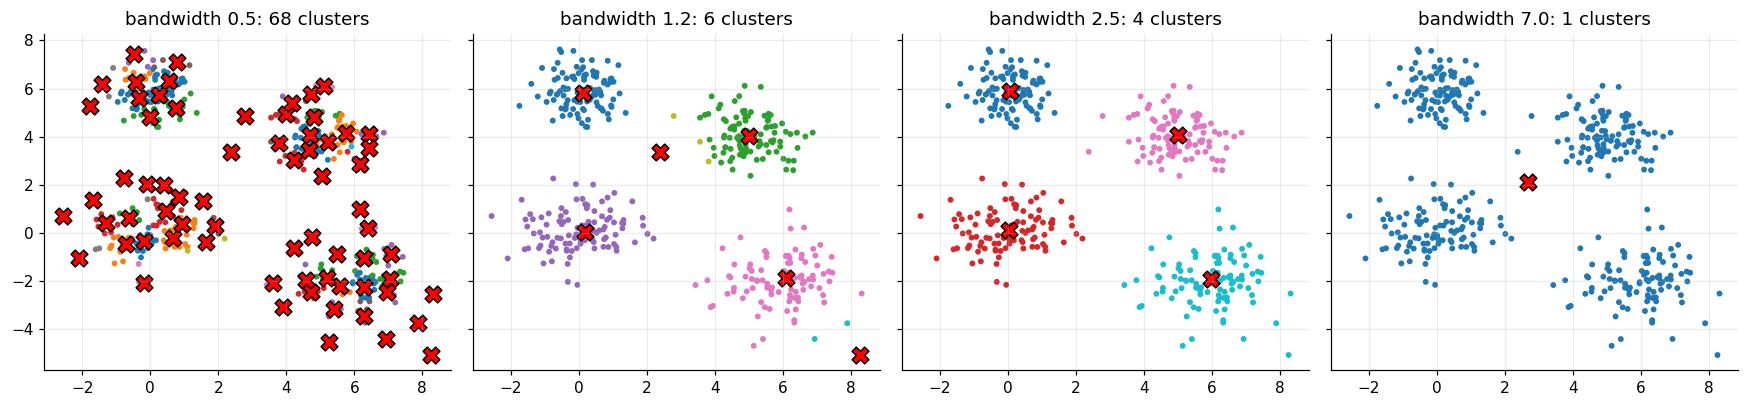

estimate_bandwidth(X) = 4.69


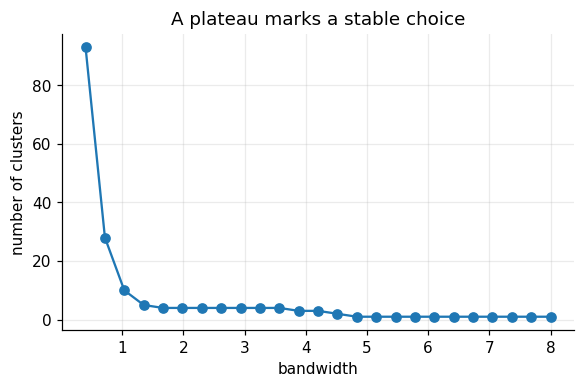

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharex=True, sharey=True)
for ax, b in zip(axes, [0.5, 1.2, 2.5, 7.0]):
    mm = MeanShift(bandwidth=b).fit(X)
    ax.scatter(*X.T, c=mm.labels_, cmap="tab10", s=8); ax.scatter(*mm.cluster_centers_.T, c="red", marker="X", s=120, edgecolor="k")
    ax.set_title(f"bandwidth {b}: {len(mm.cluster_centers_)} clusters")
plt.tight_layout(); plt.show()
print("estimate_bandwidth(X) =", round(estimate_bandwidth(X), 3))

bws = np.linspace(0.4, 8, 25)
plt.figure(figsize=(6, 3.5)); plt.plot(bws, [len(MeanShift(bandwidth=b).fit(X).cluster_centers_) for b in bws], "o-")
plt.xlabel("bandwidth"); plt.ylabel("number of clusters"); plt.title("A plateau marks a stable choice"); plt.show()

## Check against a reference implementation

Same data, same settings as scikit-learn (or scipy / the real library). The assertions fail if the two disagree.

In [5]:
import numpy as np
from sklearn.cluster import MeanShift as SklearnMeanShift
from sklearn.cluster import estimate_bandwidth as sklearn_estimate_bandwidth
from sklearn.datasets import make_blobs
from sklearn.metrics import adjusted_rand_score

X, truth = make_blobs(n_samples=300, centers=4, cluster_std=0.7, random_state=11)

bw_ours, bw_theirs = estimate_bandwidth(X, 0.2), sklearn_estimate_bandwidth(X, quantile=0.2)
print("estimated bandwidth: ours=%.4f sklearn=%.4f" % (bw_ours, bw_theirs))
assert np.isclose(bw_ours, bw_theirs)

ours = MeanShift(bandwidth=bw_ours).fit(X)
theirs = SklearnMeanShift(bandwidth=bw_theirs).fit(X)
print("clusters found (k was never given): ours=%d sklearn=%d" % (len(ours.cluster_centers_), len(theirs.cluster_centers_)))
print("modes agree: max centre difference after sorting = %.2e"
      % np.abs(np.sort(ours.cluster_centers_, axis=0) - np.sort(theirs.cluster_centers_, axis=0)).max())
print("agreement with sklearn labels (ARI) = %.4f   with true blobs = %.4f"
      % (adjusted_rand_score(ours.labels_, theirs.labels_), adjusted_rand_score(ours.labels_, truth)))
assert len(ours.cluster_centers_) == len(theirs.cluster_centers_)
assert adjusted_rand_score(ours.labels_, theirs.labels_) > 0.99

estimated bandwidth: ours=1.6743 sklearn=1.6743


clusters found (k was never given): ours=4 sklearn=4
modes agree: max centre difference after sorting = 5.33e-15
agreement with sklearn labels (ARI) = 1.0000   with true blobs = 1.0000


## Tests

Plain `assert` tests that check the invariants of the algorithm.

In [6]:
import numpy as np


def _blobs(seed=0):
    rng = np.random.default_rng(seed)
    centers = np.array([[0.0, 0.0], [8.0, 0.0], [4.0, 7.0]])
    X = np.vstack([rng.normal(c, 0.6, (50, 2)) for c in centers])
    return X, centers


def test_finds_the_number_of_clusters_by_itself():
    X, centers = _blobs()
    model = MeanShift(bandwidth=2.0).fit(X)
    assert len(model.cluster_centers_) == 3          # nobody told it k = 3
    for c in centers:                                 # every true centre has a found mode nearby
        assert np.linalg.norm(model.cluster_centers_ - c, axis=1).min() < 0.5
    assert [len(set(model.labels_[i * 50:(i + 1) * 50])) for i in range(3)] == [1, 1, 1]


def test_bandwidth_controls_granularity():
    X, _ = _blobs()
    small = len(MeanShift(bandwidth=0.4).fit(X).cluster_centers_)
    right = len(MeanShift(bandwidth=2.0).fit(X).cluster_centers_)
    huge = len(MeanShift(bandwidth=30.0).fit(X).cluster_centers_)
    assert small > right == 3 > huge == 1


def test_default_bandwidth_is_estimated_and_predict_assigns_new_points():
    X, centers = _blobs(1)
    model = MeanShift().fit(X)
    assert model.bandwidth_ == estimate_bandwidth(X)
    near_each_center = model.predict(centers + 0.1)
    assert len(set(near_each_center)) == len(near_each_center) == 3

In [7]:
tests = [(name, fn) for name, fn in list(globals().items()) if name.startswith("test_") and callable(fn)]
for name, fn in tests:
    fn()
    print("PASS", name)
print(f"\nall {len(tests)} tests passed")

PASS test_finds_the_number_of_clusters_by_itself
PASS test_bandwidth_controls_granularity
PASS test_default_bandwidth_is_estimated_and_predict_assigns_new_points

all 3 tests passed


## Takeaways

- **Use it** when you don't know `k` and clusters have arbitrary shape, e.g. image segmentation or tracking (the classic OpenCV CamShift). It is a mode-seeking, non-parametric method.
- **Cost:** `O(n²)` per iteration, so it suits thousands of points, not millions.
- **Pitfalls:** the result hinges on one number (`bandwidth`), a single global bandwidth handles varying densities poorly, and it is slow.
- **Interview line:** *"Gradient ascent on a kernel density estimate: shift each point to the mean of its window until convergence; points ending at the same mode share a cluster."*